In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True,
               cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
import pygam

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.timescales import (create_ints_dataframe_custom_grouping, convert_data_dict,
                             average_data_dict_converted, compute_deflections)
from src.plotting import create_sydnor_sa_colormap
from src.gams import (fit_all_panels, apply_region_mask,
                      get_series_colors, get_draw_order, add_colorbar, style_ax)
from snaplab_tools.plotting.plotting import plot_correlation

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
from sklearn.linear_model import LinearRegression

def residualize(y, covariates):
    """Regress covariates out of y; return residuals (NaN preserved)."""
    mask  = ~np.isnan(y)
    resid = np.full(len(y), np.nan)
    if mask.sum() < 10:
        return resid
    lr = LinearRegression().fit(covariates[mask], y[mask])
    resid[mask] = y[mask] - lr.predict(covariates[mask])
    return resid

# Load data

In [3]:
dataset       = 'HCP-D'
which_modality = 'FMRI'
# output_type   = 'timescale_auc_zero_crossing'
output_type   = 'timescale_auc_zero_crossing_bp-0.01-0.08hz'
# output_type   = 'timescale_auc_zero_crossing_bp-0.08-0.15hz'

notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   output_type=output_type, use_resids=True)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       565 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7714.75it/s]


2760
timescale_auc_zero_crossing_bp-0.01-0.08hz


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 8043.66it/s]


2760


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8358.90it/s]

2760
Number of subjects: 552


In [4]:
timescales_processor = notebook_data['timescales_processor']
data_dict            = notebook_data['data_dict']
results_dir          = notebook_data['results_dir']

if dataset == 'HCP-D':
    parcellation  = 'schaefer_400-7'
    sa_axis_file  = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                 'schaefer400-7_sa-axis.npy')
elif dataset in ('PNC', 'NKI', 'HBN'):
    parcellation  = 'schaefer_400-17'
    sa_axis_file  = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                 'schaefer400-17_sa-axis.npy')
sa_axis = sp.stats.rankdata(np.load(sa_axis_file))

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
os.makedirs(nas_scratch_dir, exist_ok=True)

# Prepare data

In [5]:
timescales_processor.match_registry_to_behavior()
df_behavior = timescales_processor.df_behavior_matched.copy()
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs      = len(subject_ids)
print(f'Number of subjects: {n_subs}')

if dataset == 'HCP-D':
    rest_scan = 'task-Rest'
    task_scan = 'tfMRICARITPA'
elif dataset == 'PNC':
    rest_scan = 'rest'
    task_scan = 'frac2back'
elif dataset == 'HBN':
    rest_scan = 'rest'
    task_scan = None

data_dict_tsnr      = notebook_data['data_dict_tsnr']
data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_centiles  = convert_data_dict(data_dict, timescales_processor.scan_registry,
                                        brain_map=sa_axis)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_all_rest=True)
data_dict_centiles  = average_data_dict_converted(data_dict_centiles,  average_all_rest=True)
df_tsnr             = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_all_rest=True)

Number of subjects: 552
rfMRIREST1PA (552, 400)
rfMRIREST2PA (552, 400)
tfMRICARITPA (552, 400)
tfMRIEMOTIONPA (552, 400)
tfMRIGUESSINGPA (552, 400)
rfMRIREST1PA (552, 10)
rfMRIREST2PA (552, 10)
tfMRICARITPA (552, 10)
tfMRIEMOTIONPA (552, 10)
tfMRIGUESSINGPA (552, 10)


# Fit GAMs

In [6]:
age      = df_behavior['age'].values
nuisance = df_behavior[['sex', 'meanFD']].values if dataset == 'HCP-D' else None
age_grid = np.linspace(age.min(), age.max(), 200)

# Region-level data (used for regional fits and deflection computation)
rest_full = data_dict_converted[rest_scan]
try:
    task_full = data_dict_converted[task_scan]
except (KeyError, TypeError):
    task_full = data_dict_converted[rest_scan]

deflection_full = np.zeros(task_full.shape)
for i in range(n_subs):
    deflection_full[i, :] = compute_deflections(rest_full[i, :], task_full[i, :],
                                                nuisance_regression=False,
                                                standardize=False, absolute=True)

# --- Decile-binned data (panels 1 & 2) ---
rest_dec = data_dict_centiles[rest_scan]
try:
    task_dec = data_dict_centiles[task_scan]
except (KeyError, TypeError):
    task_dec = data_dict_centiles[rest_scan]

deflection_dec = np.zeros(task_dec.shape)
for i in range(n_subs):
    deflection_dec[i, :] = compute_deflections(rest_dec[i, :], task_dec[i, :],
                                               nuisance_regression=False,
                                               standardize=False, absolute=True)

n_deciles     = rest_dec.shape[1]
results_dec   = fit_all_panels(age, rest_dec, task_dec, deflection_dec, age_grid,
                               n_splines=4, lam=0.1, demean=True, show_ci=False,
                               nuisance=nuisance)

cmap          = create_sydnor_sa_colormap()
series_colors = get_series_colors('decile', n_deciles, cmap)
draw_order    = get_draw_order('decile', n_deciles)

# --- Region-level fits (panel 3) ---
# Exclude lowest 10% tSNR regions
region_mask = (df_tsnr[task_scan] < np.quantile(df_tsnr[task_scan], q=0.1)).values
rest_reg, task_reg, defl_reg, sa_axis_reg = apply_region_mask(
    region_mask, rest_full, task_full, deflection_full, sa_axis=sa_axis)

results_reg = fit_all_panels(age, rest_reg, task_reg, defl_reg, age_grid,
                             n_splines=4, lam=0.1, demean=True, show_ci=False,
                             nuisance=nuisance)
print(f'Decile shape: {deflection_dec.shape}  |  Regional shape: {defl_reg.shape}')

region_mask: excluding 40 regions, 360 remaining.
Decile shape: (552, 10)  |  Regional shape: (552, 360)


# Figure 4: multi-panel

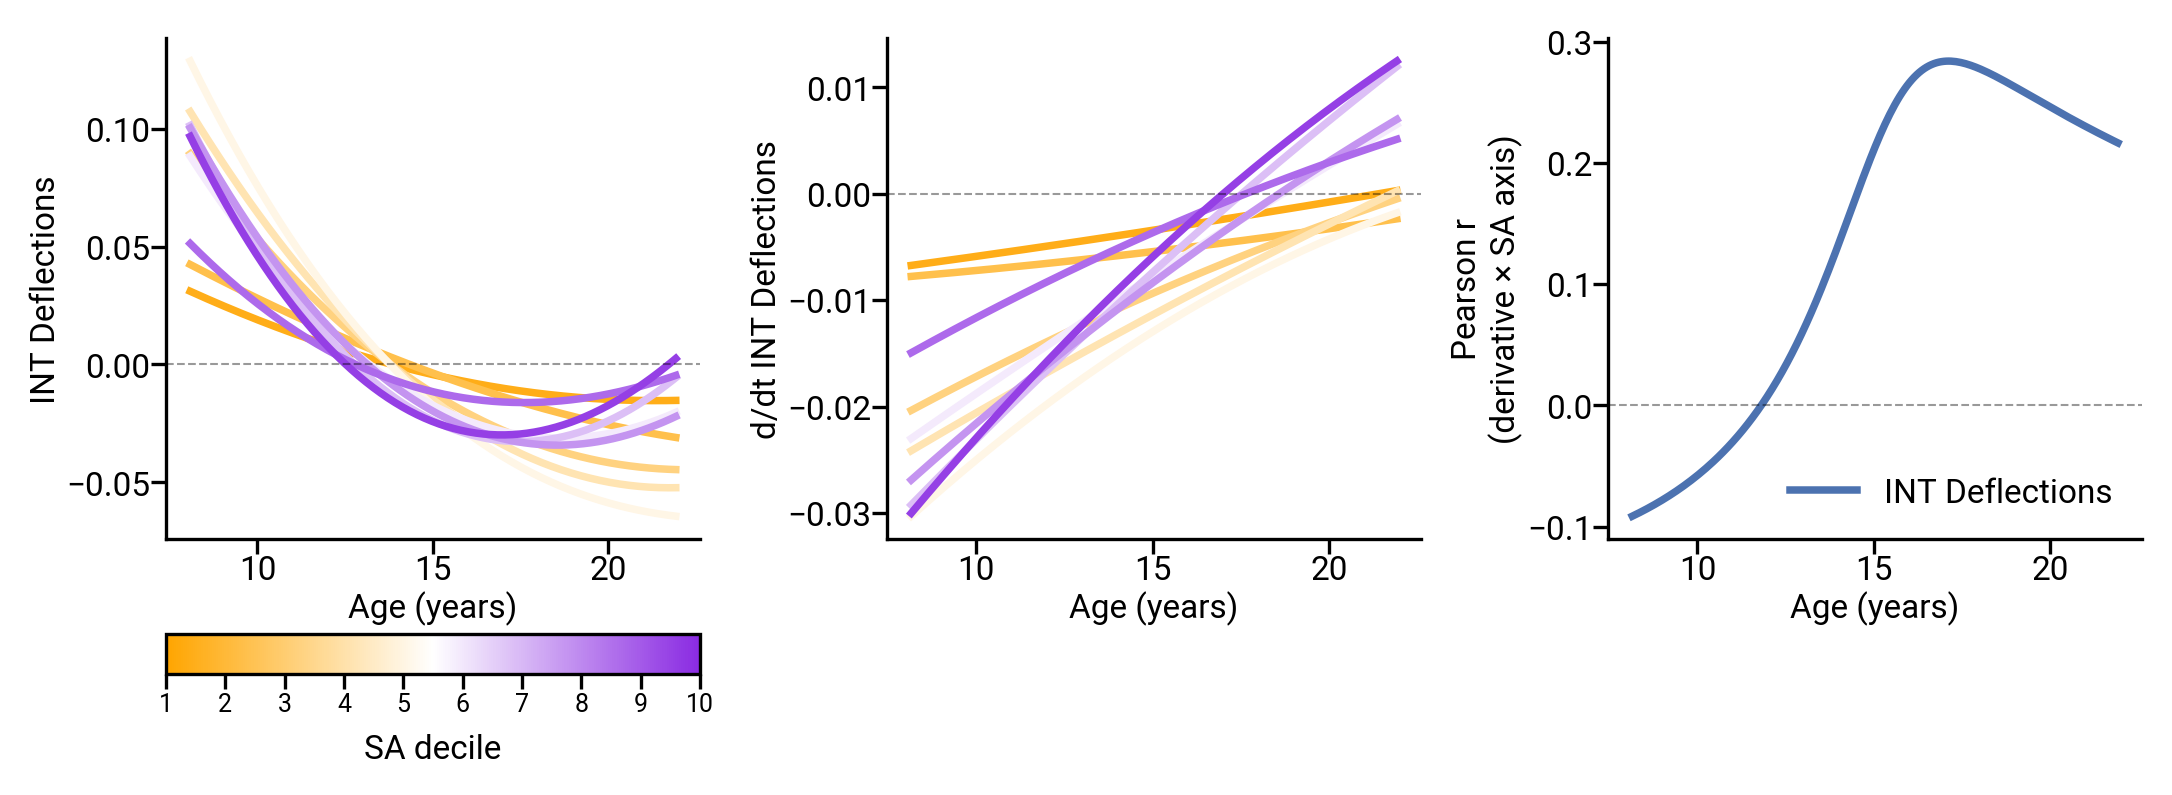

In [7]:
from matplotlib.gridspec import GridSpec

def compute_deriv_sa_corr(deriv, sa_axis_vals, method='pearson'):
    """Pearson/Spearman r between per-region SA values and derivative at each age point."""
    n_grid  = deriv.shape[1]
    rhos    = np.full(n_grid, np.nan)
    corr_fn = sp.stats.pearsonr if method == 'pearson' else sp.stats.spearmanr
    for t in range(n_grid):
        col  = deriv[:, t]
        mask = ~np.isnan(col)
        if mask.sum() > 2:
            rhos[t] = corr_fn(sa_axis_vals[mask], col[mask]).statistic
    return rhos


fig = plt.figure(figsize=(8.5, 2.75), dpi=300)
gs  = GridSpec(2, 3, figure=fig, height_ratios=[1, 0.08], hspace=0.35, wspace=0.35)

ax0     = fig.add_subplot(gs[0, 0])
ax1     = fig.add_subplot(gs[0, 1])
ax2     = fig.add_subplot(gs[0, 2])
cbar_ax = fig.add_subplot(gs[1, 0])
lw = 1.8

# --- Panel 1: GAM predictions (decile mode) ---
for i in draw_order:
    ax0.plot(age_grid, results_dec['deflection']['pred'][i],
             color=series_colors[i], lw=lw)
style_ax(ax0, 'Age (years)', 'INT Deflections', None, demean=True)

# --- Panel 2: GAM derivatives (decile mode) ---
for i in draw_order:
    ax1.plot(age_grid, results_dec['deflection']['deriv'][i],
             color=series_colors[i], lw=lw)
style_ax(ax1, 'Age (years)', 'd/dt INT Deflections', None, demean=True)

# --- Panel 3: Pearson r (regional derivative × SA axis) ---
rhos = compute_deriv_sa_corr(results_reg['deflection']['deriv'], sa_axis_reg, method='pearson')
ax2.plot(age_grid, rhos, color='#4C72B0', lw=1.8, label='INT Deflections')
ax2.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax2.set_xlabel('Age (years)', fontsize=8, labelpad=1)
ax2.set_ylabel('Pearson r\n(derivative × SA axis)', fontsize=8, labelpad=1)
ax2.tick_params(labelsize=8, pad=0.25)
ax2.legend(fontsize=8, frameon=False)
ax2.spines[['top', 'right']].set_visible(False)

# --- Single colorbar under panel 1 only ---
norm = mcolors.Normalize(vmin=1, vmax=n_deciles)
sm   = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cb.set_label('SA decile', fontsize=8)
cb.set_ticks(list(range(1, n_deciles + 1)))
cb.ax.tick_params(labelsize=6, pad=1)

fig.savefig(os.path.join(nas_scratch_dir, 'fig4_gams.png'),
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

Rows with neg→pos crossing: 199 / 360
Mean crossing age: 16.16 yrs


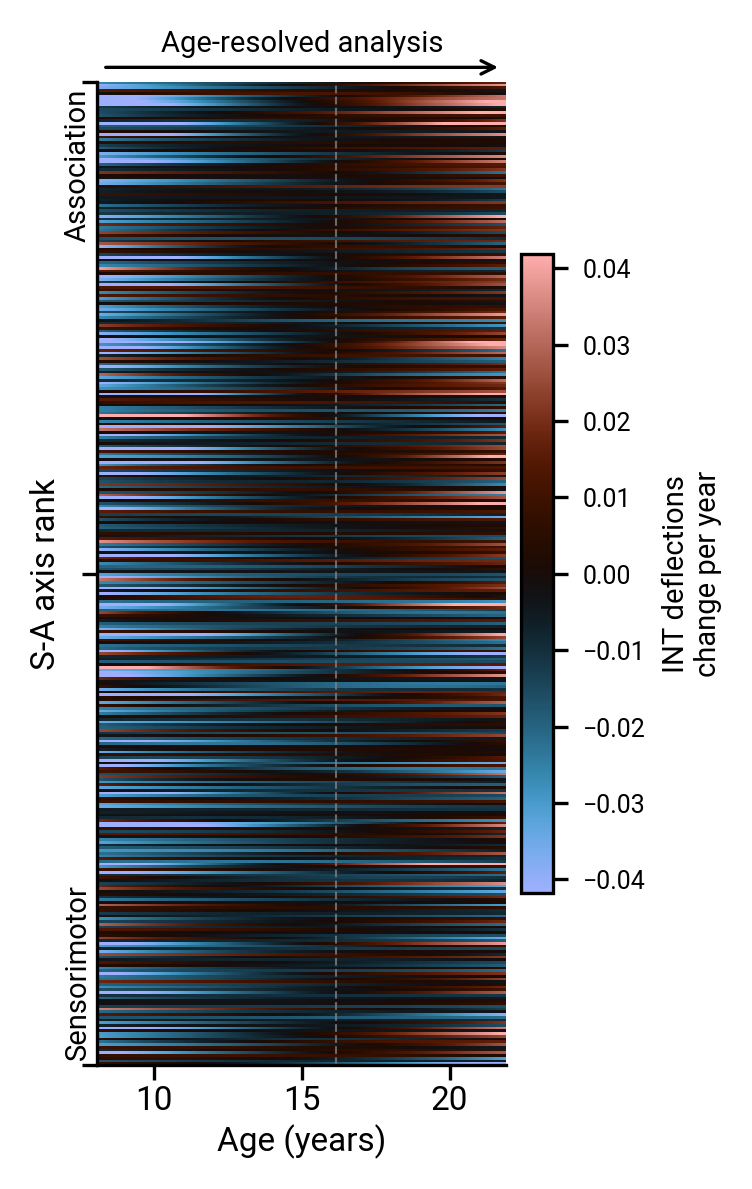

In [8]:
# --- Parameters ---
signal_type = 'deflection'   # 'rest', 'task', or 'deflection'
plot_level  = 'region' # 'region' or 'decile'
# ------------------

_signal_labels = {'rest': 'REST INTs', 'task': 'Task INTs', 'deflection': 'INT deflections'}

if plot_level == 'region':
    _deriv_raw = {'rest': results_reg['rest']['deriv'],
                  'task': results_reg['task']['deriv'],
                  'deflection': results_reg['deflection']['deriv']}[signal_type]
    # Sort by S-A axis rank: sensorimotor (low) → association (high)
    sort_idx     = np.argsort(sa_axis_reg)
    deriv_sorted = _deriv_raw[sort_idx]
    yticks       = [0, deriv_sorted.shape[0] // 2, deriv_sorted.shape[0]]
    yticklabels  = ['', '', '']
    ylabel       = 'S-A axis rank'
    bottom_label = 'Sensorimotor'
    top_label    = 'Association'
else:  # 'decile'
    deriv_sorted = {'rest': results_dec['rest']['deriv'],
                    'task': results_dec['task']['deriv'],
                    'deflection': results_dec['deflection']['deriv']}[signal_type]
    # Deciles are already ordered 0=sensorimotor … 9=association
    yticks      = np.arange(deriv_sorted.shape[0]) + 0.5
    yticklabels = [str(i + 1) for i in range(deriv_sorted.shape[0])]
    ylabel       = 'S-A axis decile'
    bottom_label = 'Sensorimotor'
    top_label    = 'Association'

n_rows = deriv_sorted.shape[0]
vmax   = np.nanpercentile(np.abs(deriv_sorted), 98)

# Find the age where each row crosses from negative to positive (first crossing only)
crossing_ages = []
for i in range(n_rows):
    row = deriv_sorted[i, :]
    for t in range(len(row) - 1):
        if row[t] < 0 and row[t + 1] >= 0:
            # Linear interpolation to exact zero crossing
            frac = -row[t] / (row[t + 1] - row[t])
            crossing_ages.append(age_grid[t] + frac * (age_grid[t + 1] - age_grid[t]))
            break
mean_cross_age = np.mean(crossing_ages) if crossing_ages else None
print(f'Rows with neg→pos crossing: {len(crossing_ages)} / {n_rows}')
if mean_cross_age is not None:
    print(f'Mean crossing age: {mean_cross_age:.2f} yrs')

fig, ax = plt.subplots(figsize=(2.5, 4), dpi=300)

im = ax.imshow(
    deriv_sorted,
    aspect='auto',
    origin='lower',
    extent=[age_grid[0], age_grid[-1], 0, n_rows],
    cmap='berlin',
    vmin=-vmax, vmax=vmax,
    interpolation='nearest',
)

if mean_cross_age is not None:
    ax.axvline(mean_cross_age, color='gray', linestyle='--', lw=0.5, alpha=0.8)

ax.set_xlabel('Age (years)', fontsize=8, labelpad=2)
ax.set_ylabel(ylabel, fontsize=8, labelpad=4)
ax.set_yticks(yticks if plot_level == 'region' else np.arange(n_rows) + 0.5)
ax.set_yticklabels(yticklabels if plot_level == 'region' else
                   [str(i + 1) for i in range(n_rows)], fontsize=7)
ax.tick_params(labelsize=8, pad=1)

ax.annotate(top_label,    xy=(age_grid[0], n_rows), xytext=(-8, -1.5), rotation=90,
            textcoords='offset points', fontsize=7, va='top',    annotation_clip=False)
ax.annotate(bottom_label, xy=(age_grid[0], 0),      xytext=(-8, 1.5), rotation=90,
            textcoords='offset points', fontsize=7, va='bottom', annotation_clip=False)

ax.annotate('', xy=(age_grid[-1], n_rows + n_rows * 0.015),
            xytext=(age_grid[0], n_rows + n_rows * 0.015),
            arrowprops=dict(arrowstyle='->', color='k', lw=0.8), annotation_clip=False)
ax.text((age_grid[0] + age_grid[-1]) / 2, n_rows + n_rows * 0.025,
        'Age-resolved analysis', ha='center', va='bottom', fontsize=7, clip_on=False)

cb = fig.colorbar(im, ax=ax, shrink=0.65, pad=0.03)
cb.set_label(f'{_signal_labels[signal_type]}\nchange per year', fontsize=7)
cb.ax.tick_params(labelsize=6)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'fig4a_heatmap.png'),
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

# Behavior: simplified age effects

In [9]:
df_behavior.head()

,age,sex,meanFD,nih_fluidcogcomp_unadjusted,nih_crycogcomp_unadjusted,nih_cogfuncogcomp_unadj,nih_eccogcomp_unadjusted,nih_totalcogcomp_unadjusted,carit_nogo_acc
subject_id,,,,,,,,,
HCD2939275V1MR,16.250000,0.0,0.097079,125.0,108.0,NaN,120.0,119.0,0.833333
HCD0051825V1MR,18.166667,0.0,0.108911,120.0,117.0,NaN,123.0,122.0,0.750000
HCD1168245V1MR,18.500000,1.0,0.157230,118.0,94.0,NaN,114.0,106.0,0.875000
HCD1057337V1MR,19.416667,1.0,0.081428,121.0,122.0,NaN,115.0,125.0,0.958333
HCD1701338V1MR,20.833333,1.0,0.108502,125.0,111.0,NaN,117.0,121.0,0.791667


In [10]:
import statsmodels.api as sm

behavior_vars = {
    'carit_nogo_acc':               'CARIT acc.',
    'nih_fluidcogcomp_unadjusted':  'Fluid Cog.',
    'nih_crycogcomp_unadjusted':  'Crystal Cog.',
    'nih_eccogcomp_unadjusted':  'Early Child Cog.',
    'nih_totalcogcomp_unadjusted':  'Total Cog.',
}
beh_colors = {'fluid_cog': '#4C72B0', 'flanker': '#DD8452', 'carit_nogo_acc': '#55A868'}

for k, label in behavior_vars.items():
    n = df_behavior[k].notna().sum()
    print(f'{label}: n={n}  mean={df_behavior[k].mean():.2f}')

CARIT acc.: n=552  mean=0.70
Fluid Cog.: n=399  mean=108.31
Crystal Cog.: n=398  mean=100.26
Early Child Cog.: n=399  mean=104.71
Total Cog.: n=399  mean=104.48


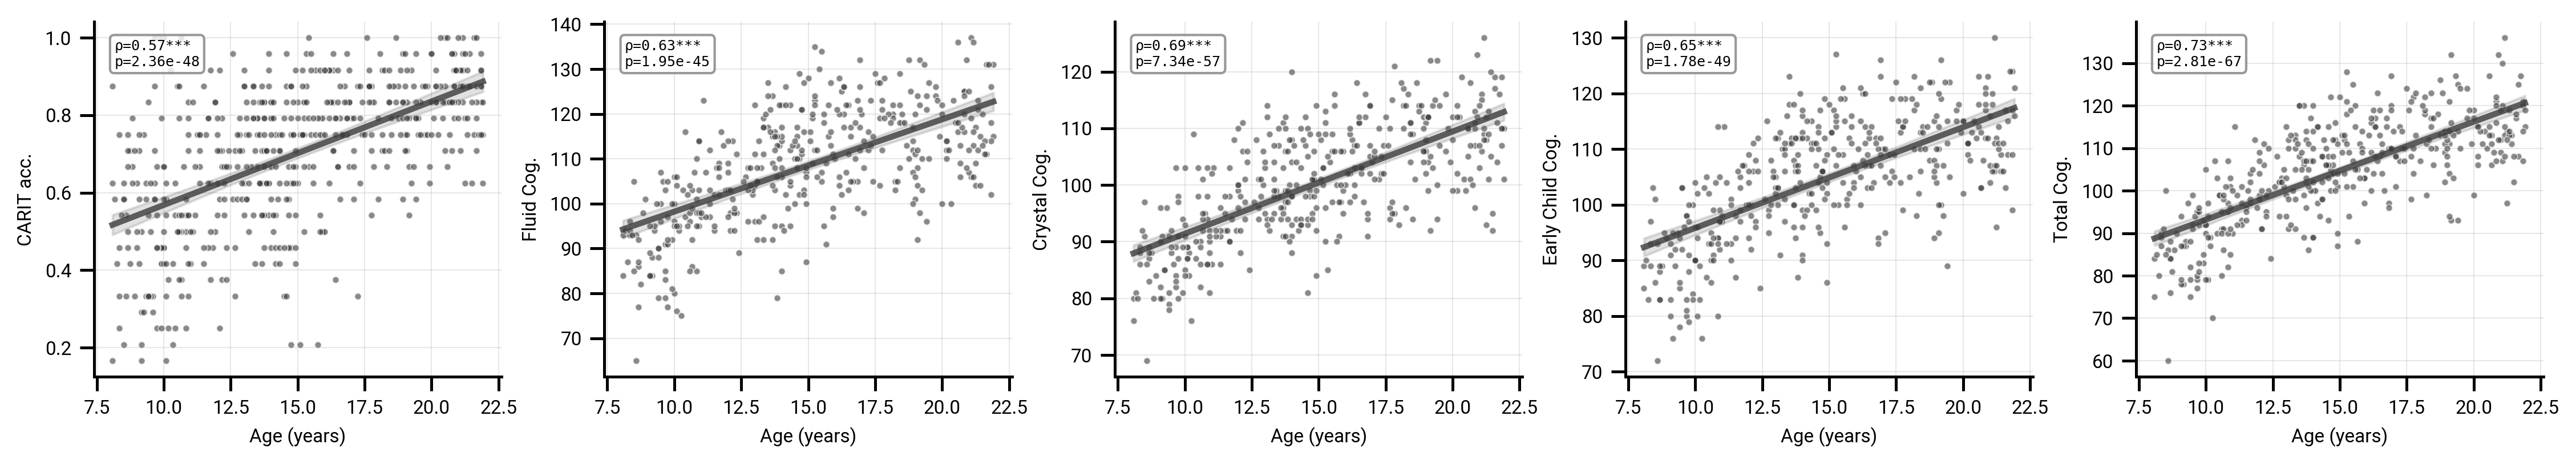

In [11]:
fig, axes = plt.subplots(1, len(behavior_vars), figsize=(3 * len(behavior_vars), 2.75), dpi=300)

for ax, (bk, label) in zip(axes, behavior_vars.items()):
    y    = df_behavior[bk]
    mask = y.notna()
    plot_correlation(age[mask], y[mask], ax,
                     x_label='Age (years)', y_label=label,
                     method='spearman', show_stats=True, fontsize=8, size=8)

fig.tight_layout()
plt.show()

In [12]:
# --- Parameters ---
n_bins       = 3                 # number of approximately equal-sized age bins
cog_measure  = 'nih_totalcogcomp_unadjusted'  # key from behavior_vars
focus_decile = 9                 # 0-indexed (9 = SA decile 10)
control_sex  = False             # residualise sex from deflection and behavior before correlating
signal_type  = 'deflection'      # 'rest', 'task', or 'deflection'
# ------------------

_dec_map = {'rest': rest_dec, 'task': task_dec, 'deflection': deflection_dec}
defl = _dec_map[signal_type][:, focus_decile].copy()

beh = df_behavior[cog_measure].values.copy()
sex = df_behavior['sex'].values.astype(float)

if control_sex:
    defl = residualize(defl, sex.reshape(-1, 1))
    beh  = residualize(beh,  sex.reshape(-1, 1))

cog_label = behavior_vars[cog_measure]
_signal_labels = {'rest': 'REST INT', 'task': 'Task INT', 'deflection': 'INT deflection'}
x_label = f'{_signal_labels[signal_type]} (SA decile {focus_decile + 1})'
y_label = f'{cog_label}'
if control_sex:
    x_label += '\n(sex residualised)'
    y_label += ' (sex residualised)'

bin_edges  = np.quantile(age, np.linspace(0, 1, n_bins + 1))
bin_labels = [f'{bin_edges[i]:.1f}–{bin_edges[i+1]:.1f} yrs' for i in range(n_bins)]
bin_assign = np.digitize(age, bin_edges[1:-1])  # 0 … n_bins-1

# fig, axes = plt.subplots(1, n_bins,
#                          figsize=(3 * n_bins, 2.75), sharey=True,
#                          dpi=300)
# if n_bins == 1:
#     axes = [axes]

# for b, (ax, label) in enumerate(zip(axes, bin_labels)):
#     m = (bin_assign == b) & ~np.isnan(defl) & ~np.isnan(beh)
#     plot_correlation(defl[m], beh[m], ax,
#                      x_label=x_label,
#                      y_label=y_label,
#                      title=f'{label} (n={m.sum()})',
#                      method='spearman', show_stats=True, fontsize=8, size=8)

# fig.tight_layout()
# fig.savefig(os.path.join(nas_scratch_dir, 'fig4_behavior_age_bins.png'),
#             dpi=1000, bbox_inches='tight', transparent=True)
# plt.show()

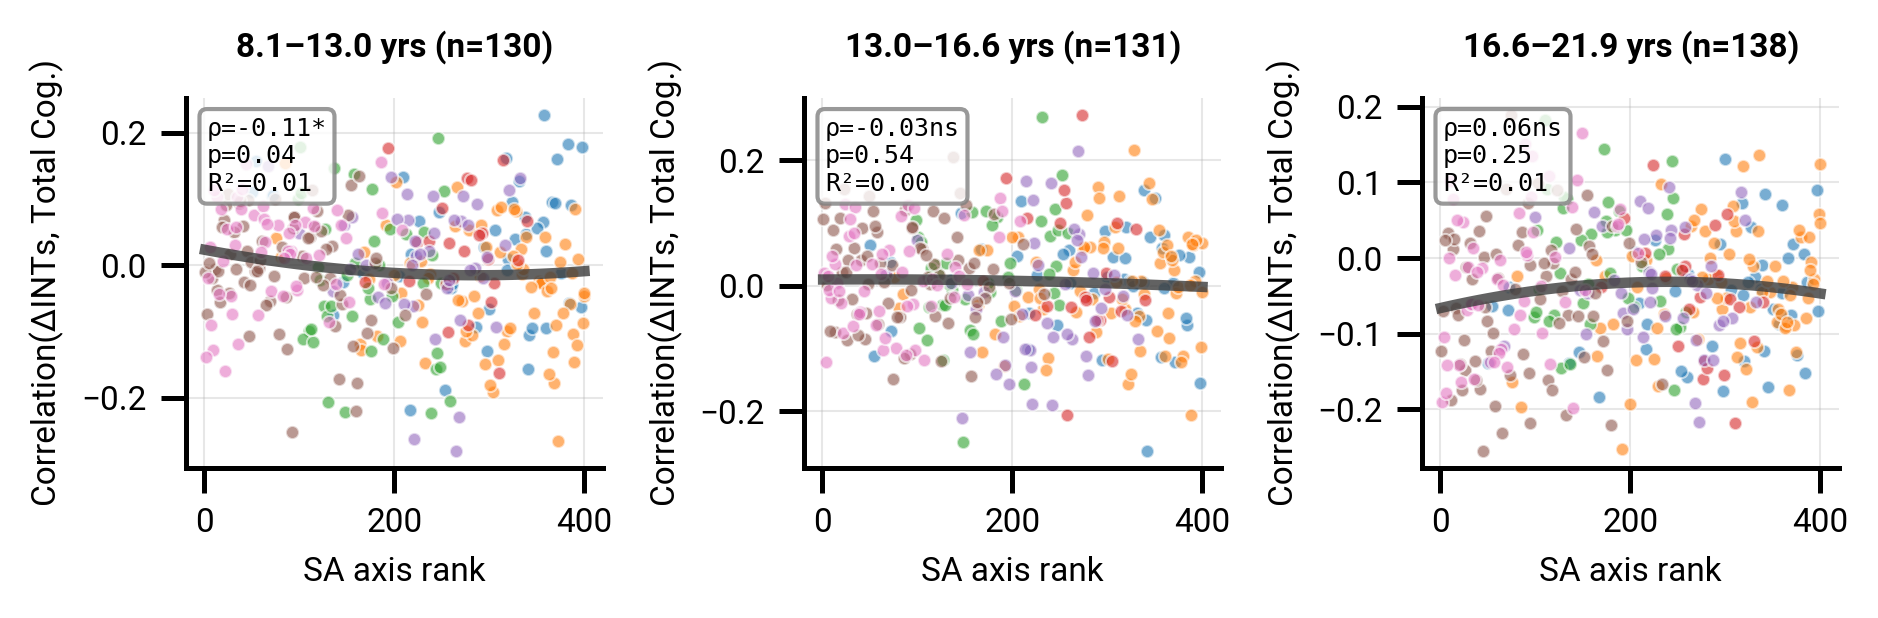

In [13]:
# Reuses: n_bins, cog_measure, control_sex, signal_type  (set in the cell above)

yeo_systems = np.array(notebook_data['supporting_data']['yeo_systems'])
yeo_reg     = yeo_systems[~region_mask]   # apply same tSNR region mask as defl_reg

beh = df_behavior[cog_measure].values.copy()
sex = df_behavior['sex'].values.astype(float)

_reg_map = {'rest': rest_reg, 'task': task_reg, 'deflection': defl_reg}
_base_reg = _reg_map[signal_type]

# Optionally residualise sex across full sample before splitting into bins
if control_sex:
    beh      = residualize(beh, sex.reshape(-1, 1))
    defl_use = np.column_stack([
        residualize(_base_reg[:, r], sex.reshape(-1, 1))
        for r in range(_base_reg.shape[1])
    ])
else:
    defl_use = _base_reg

_signal_labels = {'rest': 'REST INTs', 'task': 'Task INTs', 'deflection': 'ΔINTs'}
corr_y_label = f'Correlation({_signal_labels[signal_type]}, {behavior_vars[cog_measure]})'

bin_edges  = np.quantile(age, np.linspace(0, 1, n_bins + 1))
bin_labels = [f'{bin_edges[i]:.1f}–{bin_edges[i+1]:.1f} yrs' for i in range(n_bins)]
bin_assign = np.digitize(age, bin_edges[1:-1])

fig, axes = plt.subplots(1, n_bins,
                         figsize=(2.1 * n_bins, 2.1), sharey=False, sharex=True,
                         dpi=300)
if n_bins == 1:
    axes = [axes]

for b, (ax, blabel) in enumerate(zip(axes, bin_labels)):
    m   = (bin_assign == b) & ~np.isnan(beh)
    beh_m = beh[m]

    corr_region = np.array([
        sp.stats.pearsonr(defl_use[m, r], beh_m).statistic
        if (~np.isnan(defl_use[m, r])).sum() > 10 else np.nan
        for r in range(defl_use.shape[1])
    ])

    valid = ~np.isnan(corr_region)
    plot_correlation(sa_axis_reg[valid], corr_region[valid], ax,
                     x_label='SA axis rank',
                     y_label=corr_y_label,
                     title=f'{blabel} (n={m.sum()})',
                     data_group=yeo_reg[valid],  show_colorbar=False,
                     method='spearman', show_stats=True, fontsize=8, size=10,
                     auto_polynomial=True, models_to_test=[1, 2], model_selection_metric='variance_explained')

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, 'fig4_behavior_age_bins_regional.png'),
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

# Per-decile age × deflection GLM

In [14]:
# def fit_interaction_glm(y, deflection_vec, age, nuisance):
#     """
#     GLM: y ~ age_c + defl_c + age_c*defl_c + nuisance
#     Age and deflection are mean-centred before forming the interaction.
#     Returns (beta, t, p) for the interaction term.
#     """
#     valid = ~(np.isnan(y) | np.isnan(deflection_vec))
#     if valid.sum() < 10:
#         return np.nan, np.nan, np.nan

#     y_v      = y[valid].astype(float)
#     age_c    = age[valid] - age[valid].mean()
#     defl_c   = deflection_vec[valid] - deflection_vec[valid].mean()
#     interact = age_c * defl_c

#     X = np.column_stack([age_c, defl_c, interact])
#     if nuisance is not None:
#         X = np.column_stack([X, nuisance[valid]])
#     X = sm.add_constant(X)

#     res = sm.OLS(y_v, X).fit()
#     # interaction is always column index 3 (after const, age_c, defl_c)
#     return res.params[3], res.tvalues[3], res.pvalues[3]


# decile_x   = np.arange(1, n_deciles + 1)
# beh_colors = {'fluid_cog': '#4C72B0', 'flanker': '#DD8452', 'carit_nogo_acc': '#55A868'}

# glm_results = {bk: {'beta': [], 't': [], 'p': []} for bk in behavior_vars}

# for d in range(n_deciles):
#     defl_d = deflection_dec[:, d]
#     for bk in behavior_vars:
#         y   = df_behavior[bk].values
#         beta, t, p = fit_interaction_glm(y, defl_d, age, nuisance)
#         glm_results[bk]['beta'].append(beta)
#         glm_results[bk]['t'].append(t)
#         glm_results[bk]['p'].append(p)

# # Print summary table
# print(f"{'Behavior':<22}  {'Decile':>6}  {'beta':>8}  {'t':>7}  {'p':>8}")
# print('-' * 60)
# for bk, label in behavior_vars.items():
#     for d in range(n_deciles):
#         beta = glm_results[bk]['beta'][d]
#         t    = glm_results[bk]['t'][d]
#         p    = glm_results[bk]['p'][d]
#         sig  = '*' if p < 0.05 else ''
#         print(f'{label:<22}  {d+1:>6}  {beta:>8.4f}  {t:>7.3f}  {p:>8.4f} {sig}')

In [15]:
# from scipy.stats import t as t_dist

# n_total  = (~np.isnan(age)).sum()   # approx df for significance line
# t_thresh = t_dist.ppf(0.975, df=n_total - 6)  # p<0.05 two-tailed

# # --- Primary plot: interaction t-statistic vs SA decile ---
# fig_b, ax_b = plt.subplots(figsize=(3.5, 2.75), dpi=300)

# for bk, label in behavior_vars.items():
#     ts = np.array(glm_results[bk]['t'])
#     ax_b.plot(decile_x, ts, color=beh_colors[bk], lw=1.8, marker='o',
#               markersize=4, label=label)

# ax_b.axhline(0,        color='gray', lw=0.5, ls='--')
# ax_b.axhline( t_thresh, color='gray', lw=0.5, ls=':')
# ax_b.axhline(-t_thresh, color='gray', lw=0.5, ls=':')
# ax_b.set_xlabel('SA decile', fontsize=8, labelpad=1)
# ax_b.set_ylabel('age × deflection\ninteraction (t)', fontsize=8, labelpad=1)
# ax_b.set_xticks(decile_x)
# ax_b.tick_params(labelsize=8, pad=0.25)
# ax_b.legend(fontsize=7, frameon=False)
# ax_b.spines[['top', 'right']].set_visible(False)

# fig_b.tight_layout()
# fig_b.savefig(os.path.join(nas_scratch_dir, 'fig4_behavior_interaction.png'),
#               dpi=1000, bbox_inches='tight', transparent=True)
# plt.show()

# # --- Secondary plot: scatter for decile 10, primary behavioral outcome ---
# focus_decile = 9   # 0-indexed → SA decile 10
# focus_bk     = 'carit_nogo_acc'
# focus_label  = behavior_vars[focus_bk]

# defl_focus = deflection_dec[:, focus_decile]
# y_focus    = df_behavior[focus_bk].values
# valid      = ~(np.isnan(defl_focus) | np.isnan(y_focus))

# age_v    = age[valid]
# defl_v   = defl_focus[valid]
# y_v      = y_focus[valid]
# tertiles = np.percentile(age_v, [33.3, 66.7])
# age_grps = np.digitize(age_v, tertiles)   # 0=young, 1=mid, 2=old
# grp_colors = ['#f4a261', '#e76f51', '#264653']
# grp_labels = ['Young third', 'Middle third', 'Older third']

# fig_s, ax_s = plt.subplots(figsize=(3.0, 2.75), dpi=300)

# for g, (gc, gl) in enumerate(zip(grp_colors, grp_labels)):
#     m     = age_grps == g
#     ax_s.scatter(defl_v[m], y_v[m], s=8, color=gc, alpha=0.5, linewidths=0)
#     # regression line
#     c     = np.polyfit(defl_v[m], y_v[m], 1)
#     xr    = np.array([defl_v[m].min(), defl_v[m].max()])
#     ax_s.plot(xr, np.polyval(c, xr), color=gc, lw=1.8, label=gl)

# ax_s.set_xlabel(f'INT deflection (SA decile 10)', fontsize=8, labelpad=1)
# ax_s.set_ylabel(focus_label, fontsize=8, labelpad=1)
# ax_s.tick_params(labelsize=8, pad=0.25)
# ax_s.legend(fontsize=7, frameon=False)
# ax_s.spines[['top', 'right']].set_visible(False)

# fig_s.tight_layout()
# fig_s.savefig(os.path.join(nas_scratch_dir, 'fig4_behavior_scatter.png'),
#               dpi=1000, bbox_inches='tight', transparent=True)
# plt.show()

# Partial correlations: deflection → behavior (controlling age + sex)

In [16]:
# covariates   = df_behavior[['age', 'sex']].values.astype(float)
# sample_deciles = [0, 4, 9]   # SA deciles 1, 5, 10 (0-indexed)
# decile_labels  = ['SA decile 1', 'SA decile 5', 'SA decile 10']

# fig, axes = plt.subplots(len(sample_deciles), len(behavior_vars),
#                          figsize=(3.5 * len(behavior_vars), 3.0 * len(sample_deciles)),
#                          dpi=300)

# for row, (d, dlabel) in enumerate(zip(sample_deciles, decile_labels)):
#     defl_resid = residualize(deflection_dec[:, d], covariates)
#     for col, (bk, blabel) in enumerate(behavior_vars.items()):
#         ax  = axes[row, col]
#         beh_resid = residualize(df_behavior[bk].values, covariates)
#         mask = ~(np.isnan(defl_resid) | np.isnan(beh_resid))
#         plot_correlation(defl_resid[mask], beh_resid[mask], ax,
#                          x_label=f'INT deflection residual\n({dlabel})',
#                          y_label=f'{blabel} residual',
#                          method='pearson', show_stats=True, fontsize=8, size=8)

# fig.tight_layout()
# fig.savefig(os.path.join(nas_scratch_dir, 'fig4_behavior_partial_corr.png'),
#             dpi=1000, bbox_inches='tight', transparent=True)
# plt.show()